# Trabalho Prático Individual — Tópicos de Big Data em Python
**Nome:** SEU NOME  |  **Matrícula:** SUA MATRÍCULA

Pipeline com Pandas e PySpark sobre `vendas_bigdata_2026.csv`.

## 1. Inspeção inicial

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

CAMINHO = "dados/vendas_bigdata_2026.csv"
df = pd.read_csv(CAMINHO)
df.head()

,pedido_id,data,cliente_id,categoria,produto,regiao,canal,forma_pagamento,quantidade,preco_unitario,desconto_percentual,valor,frete,avaliacao,devolvido
0,PED001179,2026-07-22,CLI0271,Games,Joystick,Norte,App,Cartão de crédito,1,437.67,10,393.90,0.00,NaN,Não
1,PED000866,2026-09-01,CLI0132,Eletrônicos,Headset,Sudeste,App,Pix,2,208.55,5,396.25,0.00,NaN,Não
2,PED000102,2026-09-15,CLI0198,Eletrônicos,Webcam,Norte,Site,Pix,4,298.89,5,1135.78,0.00,NaN,Não
3,PED000440,2026-05-13,CLI0244,Games,Joystick,NaN,App,Pix,2,388.42,0,776.84,0.00,3.3,Não
4,PED000059,2026-05-30,CLI0140,Casa,Ventilador,Sudeste,App,Cartão de crédito,1,222.85,0,222.85,27.58,NaN,Não


In [2]:
print('shape:', df.shape)
df.info()

shape: (1200, 15)
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   pedido_id            1200 non-null   str    
 1   data                 1199 non-null   str    
 2   cliente_id           1200 non-null   str    
 3   categoria            1192 non-null   str    
 4   produto              1200 non-null   str    
 5   regiao               1188 non-null   str    
 6   canal                1200 non-null   str    
 7   forma_pagamento      1200 non-null   str    
 8   quantidade           1200 non-null   int64  
 9   preco_unitario       1200 non-null   float64
 10  desconto_percentual  1200 non-null   int64  
 11  valor                1200 non-null   float64
 12  frete                1200 non-null   float64
 13  avaliacao            854 non-null    float64
 14  devolvido            1200 non-null   str    
dtypes: float64(4), int64(2), str(9)

In [3]:
print(df.dtypes)

pedido_id                  str
data                       str
cliente_id                 str
categoria                  str
produto                    str
regiao                     str
canal                      str
forma_pagamento            str
quantidade               int64
preco_unitario         float64
desconto_percentual      int64
valor                  float64
frete                  float64
avaliacao              float64
devolvido                  str
dtype: object


In [4]:
print(df.isna().sum())

pedido_id                0
data                     1
cliente_id               0
categoria                8
produto                  0
regiao                  12
canal                    0
forma_pagamento          0
quantidade               0
preco_unitario           0
desconto_percentual      0
valor                    0
frete                    0
avaliacao              346
devolvido                0
dtype: int64


In [5]:
print('Duplicatas (linhas idênticas):', df.duplicated().sum())

Duplicatas (linhas idênticas): 8


**Quantos registros existem?** 1.200 linhas e 15 colunas.

**Problemas de qualidade identificados:**
- 8 linhas duplicadas;
- datas inválidas/ausentes (`2026-02-30`, `2026-13-05`, `31/11/2026`, `data_invalida` e 1 nula);
- `regiao` com 12 nulos e variações de grafia (`' Sudeste '`, `'sudeste'`, `'CENTRO-OESTE'`...);
- `categoria` com 8 nulos; `avaliacao` com 346 nulos (cliente não avaliou — esperado);
- 5 linhas com `quantidade = 0` e 5 com `preco_unitario <= 0`;
- 19 linhas em que `valor` não bate com `quantidade × preço × (1 − desconto/100)`.

**Primários ou secundários?** Secundários: os dados foram coletados por outra parte (a empresa/sistema de vendas) e entregues a mim para análise; eu não os coletei diretamente.

## 2. Preparação e qualidade dos dados

In [6]:
dados = df.copy()

# --- Datas: converter e identificar inválidas ---
dados["data"] = pd.to_datetime(dados["data"], format="%Y-%m-%d", errors="coerce")
datas_invalidas = df.loc[dados["data"].isna(), ["pedido_id", "data"]]
print("Datas inválidas/ausentes:", len(datas_invalidas))
print(datas_invalidas)

Datas inválidas/ausentes: 5
      pedido_id           data
237   PED000543            NaN
417   PED000669     2026-02-30
470   PED000772     31/11/2026
713   PED000808  data_invalida
1110  PED000379     2026-13-05


In [7]:
# --- Duplicatas ---
print("Duplicatas:", dados.duplicated().sum())
dados = dados.drop_duplicates().copy()
print("Linhas após remover duplicatas:", len(dados))

Duplicatas: 8
Linhas após remover duplicatas: 1192


In [8]:
# --- Ausentes ---
print(dados.isna().sum())

pedido_id                0
data                     5
cliente_id               0
categoria                8
produto                  0
regiao                  12
canal                    0
forma_pagamento          0
quantidade               0
preco_unitario           0
desconto_percentual      0
valor                    0
frete                    0
avaliacao              343
devolvido                0
dtype: int64


In [9]:
# --- Padronizar regiao ---
dados["regiao"] = dados["regiao"].str.strip().str.title()
dados["regiao"] = dados["regiao"].fillna("Não informado")
dados["categoria"] = dados["categoria"].fillna("Não informado")
print(dados["regiao"].value_counts())

regiao
Sudeste          514
Sul              238
Nordeste         232
Centro-Oeste     112
Norte             84
Não informado     12
Name: count, dtype: int64


In [10]:
# --- Quantidade e preço inválidos ---
qtd_invalida = dados["quantidade"] <= 0
preco_invalido = dados["preco_unitario"] <= 0
print("quantidade <= 0:", qtd_invalida.sum())
print("preco_unitario <= 0:", preco_invalido.sum())

quantidade <= 0: 5
preco_unitario <= 0: 5


In [11]:
# --- Coerência do valor ---
dados["valor_esperado"] = (
    dados["quantidade"]
    * dados["preco_unitario"]
    * (1 - dados["desconto_percentual"] / 100)
)
dados["valor_incoerente"] = (dados["valor"] - dados["valor_esperado"]).abs() > 0.05
print("valor incoerente (tolerância de R$ 0,05):", dados["valor_incoerente"].sum())
dados.loc[dados["valor_incoerente"], ["pedido_id", "quantidade", "preco_unitario", "desconto_percentual", "valor", "valor_esperado"]].head(10)

valor incoerente (tolerância de R$ 0,05): 19


,pedido_id,quantidade,preco_unitario,desconto_percentual,valor,valor_esperado
10,PED000821,2,301.83,0,905.49,603.6600
42,PED001109,1,171.52,5,244.41,162.9440
113,PED000992,1,-917.49,5,871.62,-871.6155
150,PED001103,0,465.91,0,465.91,0.0000
231,PED000130,2,-195.34,10,351.61,-351.6120
324,PED001120,1,84.39,5,120.25,80.1705
460,PED000530,0,103.35,0,413.40,0.0000
484,PED000260,0,199.60,10,718.56,0.0000
487,PED000824,4,-860.10,10,3096.36,-3096.3600
509,PED000006,3,240.64,5,1028.73,685.8240


In [12]:
# --- Dataset analítico ---
linhas_validas = ~(qtd_invalida | preco_invalido | dados["valor_incoerente"])
vendas = dados.loc[linhas_validas].copy()
print(f"Linhas mantidas: {len(vendas)} de {len(df)} originais")

Linhas mantidas: 1173 de 1200 originais


**Decisões tomadas:**
- **Duplicatas:** removidas (linhas 100% idênticas, mesmo pedido contado duas vezes).
- **Datas inválidas:** convertidas para `NaT`. Mantive as linhas nas análises que não dependem do tempo e as excluí apenas da evolução mensal, pois não dá para atribuí-las a um mês.
- **`regiao`/`categoria` nulas:** preenchidas com "Não informado" para não perder faturamento; `regiao` padronizada com `strip` + `title`.
- **`quantidade <= 0` e `preco_unitario <= 0`:** removidas, pois são valores impossíveis para uma venda e o `valor` registrado nelas não é confiável.
- **`valor` incoerente:** removidas, pois não é possível saber qual campo está errado (valor ou preço/quantidade/desconto). Usei `valor` como faturamento nas demais linhas, já que bate com a regra de negócio.
- **`avaliacao` nula:** mantida, pois significa que o cliente não avaliou.

## 3. Análise com Pandas

In [13]:
fat_regiao = vendas.groupby("regiao")["valor"].sum().sort_values(ascending=False)
print("1) Faturamento por região:\n", fat_regiao.round(2), "\n")
print("Maior faturamento:", fat_regiao.idxmax())

1) Faturamento por região:
 regiao
Sudeste          221696.45
Sul              111577.22
Nordeste         109187.76
Centro-Oeste      48972.60
Norte             37322.92
Não informado      6204.91
Name: valor, dtype: float64 

Maior faturamento: Sudeste


In [14]:
top5_produtos = vendas.groupby("produto")["valor"].sum().nlargest(5)
print("2) Top 5 produtos:\n", top5_produtos.round(2))

2) Top 5 produtos:
 produto
Cadeira      59544.32
Mesa         56813.67
Aspirador    41924.48
SSD 1TB      41869.38
Joystick     34735.11
Name: valor, dtype: float64


In [15]:
fat_canal = vendas.groupby("canal")["valor"].sum().sort_values(ascending=False)
print("3) Faturamento por canal:\n", fat_canal.round(2))

3) Faturamento por canal:
 canal
Site           271058.26
App            188191.72
Loja física     75711.88
Name: valor, dtype: float64


In [16]:
pagamentos = vendas["forma_pagamento"].value_counts()
print("4) Formas de pagamento:\n", pagamentos)

4) Formas de pagamento:
 forma_pagamento
Pix                  487
Cartão de crédito    452
Cartão de débito     122
Boleto               112
Name: count, dtype: int64


In [17]:
vendas["mes"] = vendas["data"].dt.to_period("M")
fat_mensal = vendas.dropna(subset=["data"]).groupby("mes")["valor"].sum()
print("5) Faturamento mensal:\n", fat_mensal.round(2))

5) Faturamento mensal:
 mes
2026-01    49056.09
2026-02    47292.85
2026-03    52689.17
2026-04    48925.86
2026-05    54810.54
2026-06    40499.81
2026-07    67486.90
2026-08    48821.57
2026-09    59631.44
2026-10    62000.09
2026-11     2378.18
Freq: M, Name: valor, dtype: float64


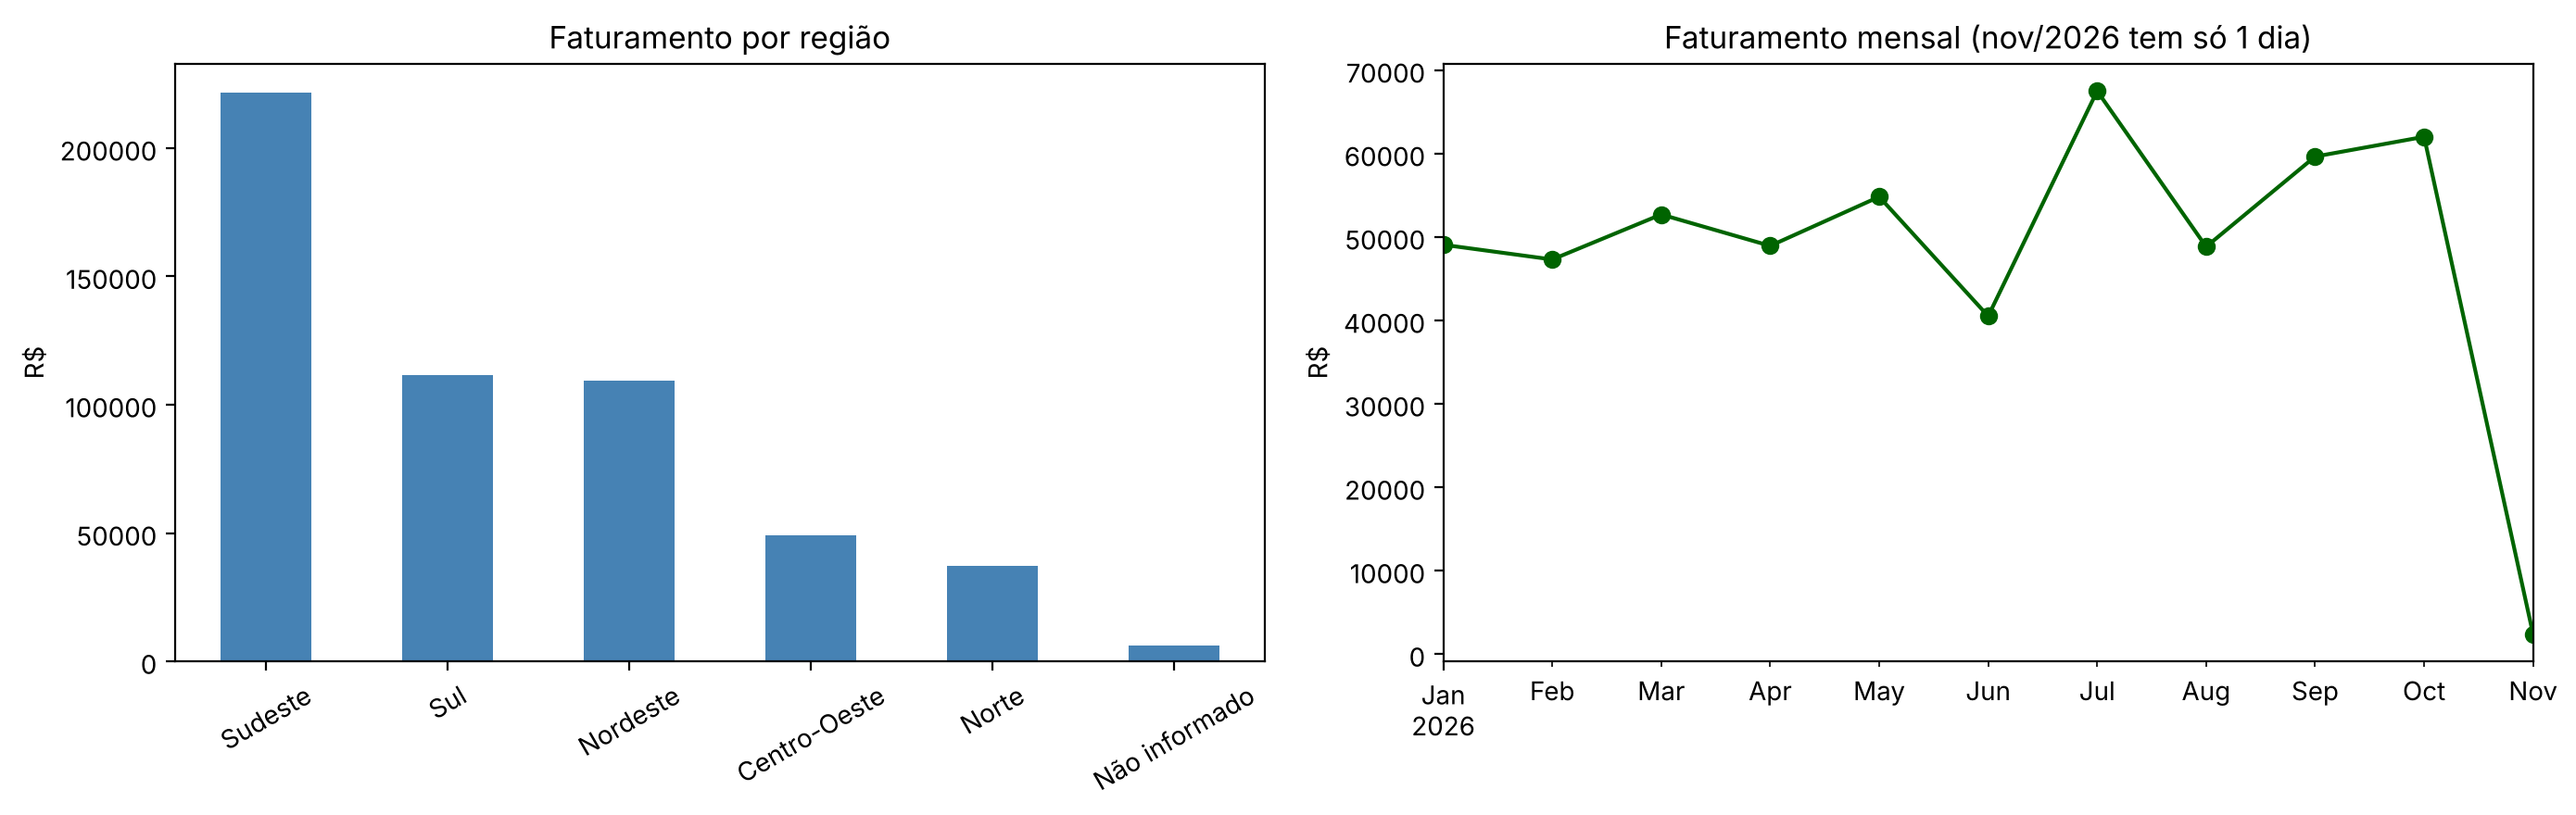

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

fat_regiao.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Faturamento por região")
axes[0].set_xlabel("")
axes[0].set_ylabel("R$")
axes[0].tick_params(axis="x", rotation=30)

fat_mensal.plot(kind="line", marker="o", ax=axes[1], color="darkgreen")
axes[1].set_title("Faturamento mensal (nov/2026 tem só 1 dia)")
axes[1].set_xlabel("")
axes[1].set_ylabel("R$")

plt.tight_layout()
plt.show()

**Conclusão**

Após a limpeza, o faturamento total foi de cerca de R$ 535 mil. A região Sudeste lidera com ~R$ 222 mil (≈41%), mais que o dobro da segunda colocada (Sul, ~R$ 112 mil). O canal Site é o maior (~R$ 271 mil), seguido de App e Loja física. Cadeira e Mesa são os produtos que mais faturam, seguidos de Aspirador, SSD 1TB e Joystick. Pix é a forma de pagamento mais usada, seguida de cartão de crédito. O faturamento mensal oscila entre ~R$ 40 mil e ~R$ 67 mil, com queda em junho e pico em julho; novembro aparece quase zerado só porque o dataset termina em 01/11. Cerca de 2% das linhas foram descartadas por inconsistências, o que reforça a necessidade de validação na origem dos dados.

## 4. PySpark DataFrame

In [19]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder.master("local[*]").appName("vendas_bigdata").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

# usa o dataset tratado (Spark lê o CSV gerado pelo Pandas)
vendas.drop(columns=["mes", "valor_incoerente"]).to_csv("resultado/vendas_tratadas.csv", index=False)
df_spark = spark.read.csv("resultado/vendas_tratadas.csv", header=True, inferSchema=True)
df_spark.printSchema()

Picked up JAVA_TOOL_OPTIONS: -XX:+IgnoreUnrecognizedVMOptions -XX:-UseBASE64Intrinsics


Picked up JAVA_TOOL_OPTIONS: -XX:+IgnoreUnrecognizedVMOptions -XX:-UseBASE64Intrinsics


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/19 01:15:51 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/11/19 01:15:51 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/usr/local/lib/python3.12/dist-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/11/19 01:15:52 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


root
 |-- pedido_id: string (nullable = true)
 |-- data: date (nullable = true)
 |-- cliente_id: string (nullable = true)
 |-- categoria: string (nullable = true)
 |-- produto: string (nullable = true)
 |-- regiao: string (nullable = true)
 |-- canal: string (nullable = true)
 |-- forma_pagamento: string (nullable = true)
 |-- quantidade: integer (nullable = true)
 |-- preco_unitario: double (nullable = true)
 |-- desconto_percentual: integer (nullable = true)
 |-- valor: double (nullable = true)
 |-- frete: double (nullable = true)
 |-- avaliacao: double (nullable = true)
 |-- devolvido: string (nullable = true)
 |-- valor_esperado: double (nullable = true)



In [20]:
resumo_spark = (
    df_spark
    .filter(F.col("valor") > 0)                         # transformação
    .groupBy("regiao")                                  # transformação
    .agg(
        F.round(F.sum("valor"), 2).alias("faturamento_total"),
        F.countDistinct("pedido_id").alias("qtd_pedidos"),
        F.sum("quantidade").alias("qtd_itens"),
    )                                                   # transformação
    .orderBy(F.col("faturamento_total").desc())         # transformação
)
resumo_spark.show()                                     # ação

+-------------+-----------------+-----------+---------+
|       regiao|faturamento_total|qtd_pedidos|qtd_itens|
+-------------+-----------------+-----------+---------+
|      Sudeste|        221696.45|        509|      969|
|          Sul|        111577.22|        230|      458|
|     Nordeste|        109187.76|        230|      453|
| Centro-Oeste|          48972.6|        110|      215|
|        Norte|         37322.92|         83|      160|
|Não informado|          6204.91|         11|       23|
+-------------+-----------------+-----------+---------+



In [21]:
# Salva o resumo regional exigido na estrutura do projeto
resumo_spark.toPandas().to_csv("resultado/resumo_regioes.csv", index=False)
pd.read_csv("resultado/resumo_regioes.csv")

/usr/local/lib/python3.12/dist-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/usr/local/lib/python3.12/dist-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,regiao,faturamento_total,qtd_pedidos,qtd_itens
0,Sudeste,221696.45,509,969
1,Sul,111577.22,230,458
2,Nordeste,109187.76,230,453
3,Centro-Oeste,48972.60,110,215
4,Norte,37322.92,83,160
5,Não informado,6204.91,11,23


**Transformações:** `filter`, `groupBy`, `agg` e `orderBy` — são *lazy*: apenas constroem o plano de execução (DAG).

**Ação:** `show()` (também seria `count()`, `collect()`, `toPandas()`) é quem dispara a execução do processamento.

**Por que `groupBy` exige redistribuição (shuffle)?** Linhas da mesma chave (ex.: mesma região) podem estar em partições/nós diferentes. Para agregá-las, o Spark precisa mover os dados pela rede para que todas as linhas de uma chave fiquem na mesma partição. É uma operação de *wide transformation*, cara em rede e disco.

## 5. Spark SQL

In [22]:
df_spark.createOrReplaceTempView("vendas")

spark.sql("""
    SELECT categoria,
           COUNT(*) AS qtd_pedidos,
           SUM(CASE WHEN devolvido = 'Sim' THEN 1 ELSE 0 END) AS qtd_devolvidos,
           ROUND(100.0 * SUM(CASE WHEN devolvido = 'Sim' THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_devolucao
    FROM vendas
    WHERE categoria <> 'Não informado'
    GROUP BY categoria
    ORDER BY pct_devolucao DESC
""").show()

+-----------+-----------+--------------+-------------+
|  categoria|qtd_pedidos|qtd_devolvidos|pct_devolucao|
+-----------+-----------+--------------+-------------+
|       Casa|        237|            18|         7.59|
|Eletrônicos|        240|            18|         7.50|
| Escritório|        220|            13|         5.91|
|      Games|        232|            12|         5.17|
| Acessórios|        236|            11|         4.66|
+-----------+-----------+--------------+-------------+



Pergunta respondida: **qual a taxa de devolução por categoria?** (diferente da análise por região da seção 4).

## 6. HDFS e escalabilidade

- **NameNode:** mestre do HDFS; guarda os metadados (árvore de diretórios, quais blocos formam cada arquivo e em quais DataNodes estão) e coordena acessos. Não armazena os dados.
- **DataNodes:** armazenam fisicamente os blocos do arquivo, atendem leituras/escritas e reportam ao NameNode.
- **Sem heartbeats:** após um tempo limite, o NameNode marca o DataNode como morto e re-replica os blocos que ele guardava em outros nós, restaurando o fator 3.
- **Por que replicação ajuda:** com 3 cópias em nós (e racks) diferentes, a falha de um nó não torna o dado indisponível, e leituras podem ser feitas em qualquer réplica.

## 7. Auditoria de Machine Learning

**Problema:** *data leakage*. O `StandardScaler` é ajustado (`fit`) com **todo** o dataset antes do `train_test_split`, então média e desvio padrão do conjunto de teste vazam para o treino. A avaliação fica otimista e não representa dados realmente novos. O correto é ajustar o scaler **somente no treino** e apenas aplicar `transform` no teste — o `Pipeline` garante isso.

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X = vendas[["quantidade", "preco_unitario", "desconto_percentual", "frete"]]
y = (vendas["devolvido"] == "Sim").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

modelo = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000)),
])
modelo.fit(X_train, y_train)          # scaler ajustado só no treino
print("Acurácia no teste:", round(modelo.score(X_test, y_test), 3))

Acurácia no teste: 0.936


In [24]:
spark.stop()